# Validação de Opções e Superfícies de Volatilidade (Manuais B3 e Bloomberg)

Este caderno documenta e valida os modelos de precificação de opções e construção de superfícies de volatilidade implícita implementados no núcleo Cython `options_core` e nos módulos `bz_pricing.instruments.options` e `bz_pricing.volatility`:
1. Opções sobre ações, ETFs e índices (`EquityOption`, modelos Black-Scholes-Merton europeu e árvore binomial Cox-Ross-Rubinstein americana, além de `CorradoSuOption`).
2. Opções sobre moedas (`FXOption`, Garman-Kohlhagen com curva `PRE` e cupom cambial e ajuste de *fixing*) e opções sobre juros (`IDIOption` e `DI1Option`).
3. Calibração e interpolação de superfícies de volatilidade (`SVISlice`, `SABRSlice`, `VolatilitySurface`, conversão $\Delta \leftrightarrow K$, variância total $\sigma^2 T$ e auditoria de não arbitragem).
4. Precificação em lote de carteira de opções via Cython (`price_options_portfolio`).

In [1]:
import datetime, math, os, time
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bz_pricing.curves import CurveManager
from bz_pricing.instruments import (
    EquityOption,
    FXOption,
    IDIOption,
    DI1Option,
    CorradoSuOption,
    price_options_portfolio,
)
from bz_pricing.volatility import (
    SVISlice,
    SABRSlice,
    VolatilitySurface,
    delta_to_strike,
    strike_to_delta,
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
ref_dt = datetime.date(2026, 11, 12)
cm = CurveManager(allow_download=True)
curva_pre = cm.get_curve('PRE', ref_dt)

## 1. Opções de Renda Variável (`EquityOption` e `CorradoSuOption`)

Avaliam-se opções europeias e americanas com taxa livre de risco contínua $r_n = \ln(1 + T_{	ext{PreDI1},n})$ extraída da curva `PRE` da B3, cálculo completo de gregas de primeira e segunda ordem (`delta`, `gamma`, `vega`, `theta`, `rho`, `vanna` e `volga`), verificação da paridade *Put-Call*, inversão de volatilidade implícita em Cython e comparação com o modelo de Corrado & Su.

In [2]:
mat_eq = datetime.date(2027, 5, 17)
spot_eq, strike_eq, vol_eq, q_div = 38.50, 40.00, 0.32, 0.04

c_eu = EquityOption('PETRC400', mat_eq, strike_eq, 'CALL', 'EUROPEAN')
p_eu = EquityOption('PETRO400', mat_eq, strike_eq, 'PUT',  'EUROPEAN')
p_am = EquityOption('PETRO400A', mat_eq, strike_eq, 'PUT', 'AMERICAN')
cs_c = CorradoSuOption('PETRC400CS', mat_eq, strike_eq, 'CALL')

mc = c_eu.risk_metrics(ref_dt, spot_eq, curva_pre, vol_eq, q_div)
mp = p_eu.risk_metrics(ref_dt, spot_eq, curva_pre, vol_eq, q_div)
ma = p_am.risk_metrics(ref_dt, spot_eq, curva_pre, vol_eq, q_div, crr_steps=300)

paridade_lhs = mc['price'] - mp['price']
paridade_rhs = spot_eq * math.exp(-mc['q_cont'] * mc['T']) - strike_eq * math.exp(-mc['r_cont'] * mc['T'])
iv_rec = c_eu.implied_volatility(ref_dt, mc['price'], spot_eq, curva_pre, q_div)
p_cs = cs_c.price(ref_dt, spot_eq, curva_pre, vol_eq, kappa3=-0.35, kappa4=4.2, carry_or_div_yield=q_div)

print(f"Erro na paridade Put-Call: {abs(paridade_lhs - paridade_rhs):.2e}")
print(f"Vol implícita recuperada:  {iv_rec*100:.6f}% (entrada: {vol_eq*100:.6f}%)")
print(f"Corrado & Su (kappa3=-0.35, kappa4=4.2): R$ {p_cs:.4f} vs BSM: R$ {mc['price']:.4f}")

pd.DataFrame([
    {'ativo': c_eu.ticker, 'tipo': 'CALL EU', **mc},
    {'ativo': p_eu.ticker, 'tipo': 'PUT EU',  **mp},
    {'ativo': p_am.ticker, 'tipo': 'PUT AM (CRR)', **ma},
])[['ativo', 'tipo', 'du', 'price', 'delta', 'gamma', 'vega_1pct', 'theta_du', 'rho', 'vanna', 'volga']]

Erro na paridade Put-Call: 0.00e+00
Vol implícita recuperada:  32.000000% (entrada: 32.000000%)
Corrado & Su (kappa3=-0.35, kappa4=4.2): R$ 3.2830 vs BSM: R$ 3.5029


,ativo,tipo,du,price,delta,gamma,vega_1pct,theta_du,rho,vanna,volga
0,PETRC400,CALL EU,125.0,3.502860,0.545791,0.044638,0.105024,-0.019182,8.685567,0.100752,-0.388302
1,PETRO400,PUT EU,125.0,3.253095,-0.434942,0.044638,0.105024,-0.005760,-9.919824,0.100752,-0.388302
2,PETRO400A,PUT AM (CRR),125.0,3.528446,-0.434942,0.044638,0.105024,-0.005760,-9.919824,0.100752,-0.388302


## 2. Opções de Câmbio (`FXOption`) e Juros (`IDIOption` e `DI1Option`)

Para moedas (`USD/BRL`), a taxa doméstica $r_n$ provém da curva `PRE` e a taxa estrangeira contínua $q_n$ é derivada do cupom cambial limpo (`DOC` em base `DC/360`), com opção de ajuste de *fixing* ($t-1$). Para juros, validam-se opções sobre `IDI` e sobre futuro de `DI1` com inversão de volatilidade implícita via Black-76.

In [3]:
mat_fx = datetime.date(2027, 2, 1)
fx_c = FXOption('DOLC580', mat_fx, 5.80, 'CALL')
fx_p = FXOption('DOLP580', mat_fx, 5.80, 'PUT')
m_fx_c = fx_c.risk_metrics(ref_dt, spot_ptax=5.75, pre_rate_or_curve=curva_pre, cupom_limpo_or_curve=0.055, vol=0.16)
m_fx_adj = fx_c.risk_metrics(ref_dt, spot_ptax=5.75, pre_rate_or_curve=curva_pre, cupom_limpo_or_curve=0.055, vol=0.16, fixing_vol_adjust=True)

idi_c = IDIOption('IDIC300', mat_fx, 295000.0, 'CALL')
m_idi = idi_c.risk_metrics(ref_dt, idi_spot=286000.0, pre_rate_or_curve=curva_pre, vol=0.045)
iv_idi = idi_c.implied_volatility(ref_dt, m_idi['price'], idi_spot=286000.0, pre_rate_or_curve=curva_pre)

di1_c = DI1Option('DI1C15', mat_fx, datetime.date(2028, 1, 3), strike_rate=0.15, option_type='CALL')
m_di1 = di1_c.risk_metrics(ref_dt, pu_c=97100.0, pu_l=85800.0, vol=0.18)
iv_di1 = di1_c.implied_volatility(ref_dt, m_di1['price'], pu_c=97100.0, pu_l=85800.0)

pd.DataFrame([
    {'contrato': fx_c.ticker, 'modelo': 'Garman-Kohlhagen', 'preco': m_fx_c['price'], 'delta': m_fx_c['delta'], 'vega_1pct': m_fx_c['vega_1pct'], 'iv_check_%': fx_c.implied_volatility(ref_dt, m_fx_c['price'], 5.75, curva_pre, 0.055)*100},
    {'contrato': f'{fx_c.ticker} (fixing)', 'modelo': 'GK + Ajuste DU/(DU+1)', 'preco': m_fx_adj['price'], 'delta': m_fx_adj['delta'], 'vega_1pct': m_fx_adj['vega_1pct'], 'iv_check_%': m_fx_adj['vol_eff']*100},
    {'contrato': idi_c.ticker, 'modelo': 'Black-76 IDI', 'preco': m_idi['price'], 'delta': m_idi['delta'], 'vega_1pct': m_idi['vega_1pct'], 'iv_check_%': iv_idi*100},
    {'contrato': di1_c.ticker, 'modelo': 'Black-76 DI1 FRA', 'preco': m_di1['price'], 'delta': m_di1['delta'], 'vega_1pct': m_di1['vega_1pct'], 'iv_check_%': iv_di1*100},
])

,contrato,modelo,preco,delta,vega_1pct,iv_check_%
0,DOLC580,Garman-Kohlhagen,0.186348,0.543052,0.010407,16.000000
1,DOLC580 (fixing),GK + Ajuste DU/(DU+1),0.184828,0.543237,0.010407,15.853878
2,IDIC300,Black-76 IDI,1912.461157,0.425444,521.631422,4.500000
3,DI1C15,Black-76 DI1 FRA,188.973284,24478.434096,17.419611,18.000000


## 3. Superfícies de Volatilidade Implícita (`SVI`, `SABR`, Spline Monótono e Não Arbitragem)

Calibram-se fatias `SVISlice` em dois vencimentos (63 e 126 dias úteis) e uma fatia `SABRSlice` para taxas de juros. Em seguida, constrói-se a `VolatilitySurface`, executa-se a interpolação temporal em variância total $\sigma^2 T$, verifica-se a conversão bidirecional $\Delta \leftrightarrow K$ e audita-se a ausência de arbitragem de *strike*, borboleta e calendário.

Auditoria de não arbitragem B3: {'passed': True, 'strike_monotonicity_violations': 0, 'butterfly_violations': 0, 'calendar_violations': 0}
Conversão Delta -> Strike -> Delta (25D): K=110.9854 | Delta recuperado=0.250000
Erro máximo de ajuste SABR: 1.70e-12


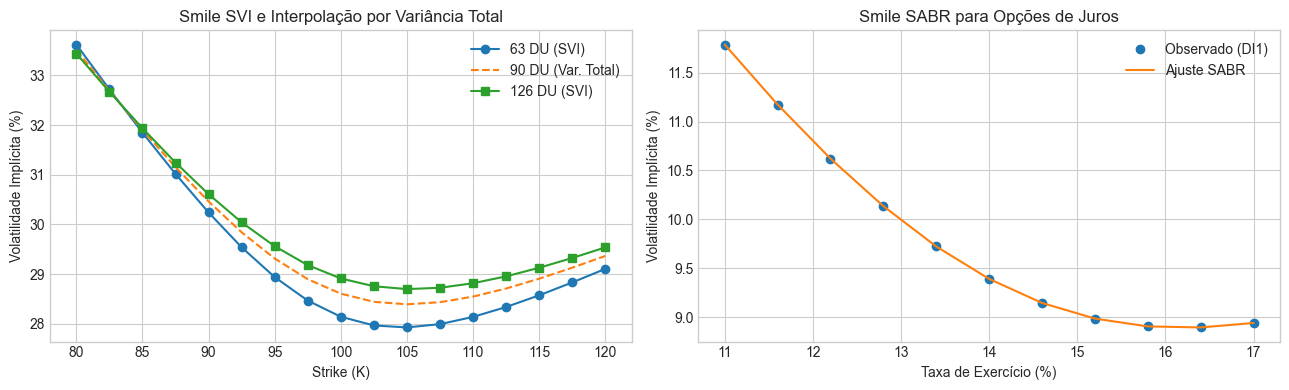

In [4]:
fwd = 100.0
k_grid = np.linspace(80.0, 120.0, 17)
log_m = np.log(k_grid / fwd)

sl_63_ref = SVISlice(a=0.015, b=0.04, rho=-0.35, m=0.0, sigma=0.12, T=63 / 252.0)
sl_126_ref = SVISlice(a=0.032, b=0.07, rho=-0.35, m=0.0, sigma=0.14, T=126 / 252.0)
sl_63_fit = SVISlice.fit(log_m, sl_63_ref.implied_vol(log_m), T=63 / 252.0)
sl_126_fit = SVISlice.fit(log_m, sl_126_ref.implied_vol(log_m), T=126 / 252.0)

surf_svi = VolatilitySurface.from_svi_slices({63: sl_63_fit, 126: sl_126_fit})
arb_res = surf_svi.check_no_arbitrage(forward_by_du=fwd, r_cont_by_du=0.13)
print('Auditoria de não arbitragem B3:', arb_res)

k_25d = delta_to_strike(0.25, fwd, 0.28, 63 / 252.0)
d_back = strike_to_delta(k_25d, fwd, 0.28, 63 / 252.0)
print(f'Conversão Delta -> Strike -> Delta (25D): K={k_25d:.4f} | Delta recuperado={d_back:.6f}')

sabr_ref = SABRSlice(alpha=0.035, beta=0.5, rho=-0.25, nu=0.35, F=0.14, T=0.5)
k_ir = np.linspace(0.11, 0.17, 11)
sabr_fit = SABRSlice.fit(0.14, k_ir, sabr_ref.implied_vol(k_ir), T=0.5, beta=0.5)
print(f'Erro máximo de ajuste SABR: {np.max(np.abs(sabr_fit.implied_vol(k_ir) - sabr_ref.implied_vol(k_ir))):.2e}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_grid, [surf_svi.get_vol(63, strike=float(k), forward=fwd)*100 for k in k_grid], 'o-', label='63 DU (SVI)')
axes[0].plot(k_grid, [surf_svi.get_vol(90, strike=float(k), forward=fwd)*100 for k in k_grid], '--', label='90 DU (Var. Total)')
axes[0].plot(k_grid, [surf_svi.get_vol(126, strike=float(k), forward=fwd)*100 for k in k_grid], 's-', label='126 DU (SVI)')
axes[0].set_title('Smile SVI e Interpolação por Variância Total')
axes[0].set_xlabel('Strike (K)')
axes[0].set_ylabel('Volatilidade Implícita (%)')
axes[0].legend()

axes[1].plot(k_ir * 100, sabr_ref.implied_vol(k_ir) * 100, 'o', label='Observado (DI1)')
axes[1].plot(k_ir * 100, sabr_fit.implied_vol(k_ir) * 100, '-', label='Ajuste SABR')
axes[1].set_title('Smile SABR para Opções de Juros')
axes[1].set_xlabel('Taxa de Exercício (%)')
axes[1].set_ylabel('Volatilidade Implícita (%)')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Benchmark de Precificação em Lote (`price_options_portfolio`)

Avalia-se o desempenho do núcleo Cython `price_options_batch` na precificação conjunta de 1.000 contratos (opções europeias e americanas com árvore binomial CRR).

In [5]:
positions = [
    {'instrument': c_eu, 'spot': spot_eq, 'pre_rate_or_curve': curva_pre, 'vol': 0.31, 'quantity': 100},
    {'instrument': p_am, 'spot': spot_eq, 'pre_rate_or_curve': curva_pre, 'vol': 0.33, 'quantity': -50},
] * 500

t0 = time.perf_counter()
df_batch = price_options_portfolio(positions, ref_dt, crr_steps=120)
elapsed = time.perf_counter() - t0
print(f'Carteira de {len(df_batch)} opções precificada em {elapsed:.4f} s')
df_batch.head(4)

Carteira de 1000 opções precificada em 0.0779 s


,ticker,option_type,exercise,quantity,price,mtm,delta,gamma,vega_1pct,theta_du,rho
0,PETRC400,CALL,EUROPEAN,100.0,3.822903,382.290282,0.590437,0.046236,0.105383,-0.022796,9.379431
1,PETRO400A,PUT,AMERICAN,-50.0,3.410730,-170.536475,-0.409640,0.043436,0.105388,-0.004232,-9.331993
2,PETRC400,CALL,EUROPEAN,100.0,3.822903,382.290282,0.590437,0.046236,0.105383,-0.022796,9.379431
3,PETRO400A,PUT,AMERICAN,-50.0,3.410730,-170.536475,-0.409640,0.043436,0.105388,-0.004232,-9.331993


## 5. Referências Normativas e Bibliográficas

- **B3 S.A. – Brasil, Bolsa, Balcão.** *Manual de Apreçamento — Contratos de Opções*. São Paulo: B3, 2026. Disponível em: <https://www.b3.com.br/pt_br/market-data-e-indices/servicos-de-dados/market-data/consultas/mercado-de-derivativos/>.
- **B3 S.A. – Brasil, Bolsa, Balcão.** *Anexo de Parâmetros Mensais — Opções e Manual de Curvas*. São Paulo: B3. Disponível em: <https://www.b3.com.br/>.
- **Bloomberg L.P.** *Equity Implied Volatility Surface: Option Pricing & Risk Management*. New York: Bloomberg Finance L.P. Disponível em: <https://www.bloomberg.com/professional/>.